# Comparing conditions after FlowSOM clustering

After clustering, the usual next question is what differs between conditions. There are two kinds of differences:

1. Differential abundance (DA): does the share of a cell population change between conditions?
2. Differential state (DS): within a population, does the level of a functional marker (for example a phosphorylated signalling protein) change?

In this tutorial we answer both questions with existing scverse tools: pytometry for reading and clustering, scanpy for per-sample summaries and [pertpy](https://pertpy.readthedocs.io) for the statistical tests.

We compare bone marrow of healthy donors with bone marrow of patients with acute myeloid leukaemia (AML), measured by mass cytometry without stimulation. In AML, immature myeloid cells (blasts) expand and displace normal blood formation, so we expect large differences in abundance.

One rule matters throughout: the cells of one sample are not independent replicates. Each sample contains thousands of cells, and a test that treats all cells as independent observations finds tiny, irrelevant differences "significant" (pseudoreplication). We therefore first summarise each sample, and then test on these summaries. Here every person contributes one sample, so the samples of the two groups are compared unpaired.

The tests need pertpy, which is not a dependency of pytometry. scCODA, the abundance model we use, needs pertpy's `jax` extra, and the linear models need its `de` extra:

```
pip install "pertpy[jax,de]" session-info2
```

In [1]:
import matplotlib.pyplot as plt
import anndata as ad
import pandas as pd
import pertpy as pt
import pooch
import scanpy as sc
import seaborn as sns
from statsmodels.stats.multitest import fdrcorrection

import pytometry as pm

## Download the data

The data are a subset of [Levine et al. (2015)](https://doi.org/10.1016/j.cell.2015.05.047), *Data-driven phenotypic dissection of AML reveals progenitor-like cells that correlate with prognosis*, Cell 162, 184-197. We download them from the figshare dataset *levine-CyTOF-AML-Healthy-AML-fcs* by Adriano Martinelli (2022), [doi:10.6084/m9.figshare.19867021](https://doi.org/10.6084/m9.figshare.19867021), which is shared under the [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/) license.

We use the sample table, the channel table, and the unstimulated sample (`NoDrug_Basal1`) of the 5 healthy donors H1 to H5 and of the AML patients SJ01 to SJ08. The figshare dataset contains 16 AML patients; we use only the first 8 to keep the download small (about 70 MB). `pooch` checks every file against its checksum and keeps it in a cache folder, so it is downloaded only once.

In [2]:
files = {
    "Levine_Healthy_vs_AML_sampleID.csv": (35283826, "941817465adcb627c5f2238631c95717"),
    "Levine_Healthy_vs_AML_channels.csv": (35283823, "a2b056726860cf9bbd77a7d40a293100"),
    "H1_NoDrug_Basal1_PhenoGraph.fcs": (35283802, "e8e0efa13735263784d0f910814c9417"),
    "H2_NoDrug_Basal1_PhenoGraph.fcs": (35283808, "78c30d1f167559f3a055b09e6e466c91"),
    "H3_NoDrug_Basal1_PhenoGraph.fcs": (35283811, "ac0adb28b7e9da05851510489ad5d6f9"),
    "H4_NoDrug_Basal1_PhenoGraph.fcs": (35283817, "a6a5175ddabc16d598afd01ec92519a6"),
    "H5_NoDrug_Basal1_PhenoGraph.fcs": (35283820, "6934d363beef4d47454499f8b1f7391d"),
    "SJ01_NoDrug_Basal1_PhenoGraph.fcs": (35283829, "9e9c2cd706acdde109b5ceeee1757d51"),
    "SJ02_NoDrug_Basal1_PhenoGraph.fcs": (35283832, "81ce7794259f81a50a1a9335f7901a20"),
    "SJ03_NoDrug_Basal1_PhenoGraph.fcs": (35283835, "675da39e6c8b6e61d10bf9164969fdb2"),
    "SJ04_NoDrug_Basal1_PhenoGraph.fcs": (35283841, "c5bd09bf9bea7763714aeb0ccba71363"),
    "SJ05_NoDrug_Basal1_PhenoGraph.fcs": (35283844, "2c0c3893eecb222fee2df000e54ccd78"),
    "SJ06_NoDrug_Basal1_PhenoGraph.fcs": (35283850, "1548e200dfbb66b832c4e3a0aa9ec2de"),
    "SJ07_NoDrug_Basal1_PhenoGraph.fcs": (35283856, "93a1fcf60bfeb27aa3bb650a87d88c92"),
    "SJ08_NoDrug_Basal1_PhenoGraph.fcs": (35283859, "f9640a517a31e5251f8baf52096f5ba1"),
}
paths = {
    name: pooch.retrieve(
        f"https://ndownloader.figshare.com/files/{file_id}",
        known_hash=f"md5:{md5}",
        fname=name,
        path=pooch.os_cache("pytometry"),
    )
    for name, (file_id, md5) in files.items()
}

The sample table links every FCS file to its donor and group. We keep the files we downloaded:

In [3]:
samples = pd.read_csv(paths["Levine_Healthy_vs_AML_sampleID.csv"])
samples = samples[samples["sample_ID"].isin(paths)].rename(columns={"patient": "sample_id", "tissue": "condition"})
samples["condition"] = pd.Categorical(samples["condition"], categories=["healthy", "AML"])
samples.head()

,sample_ID,sample_id,condition,ncells
0,H1_NoDrug_Basal1_PhenoGraph.fcs,H1,healthy,15394
2,H2_NoDrug_Basal1_PhenoGraph.fcs,H2,healthy,26633
3,H3_NoDrug_Basal1_PhenoGraph.fcs,H3,healthy,21246
4,H4_NoDrug_Basal1_PhenoGraph.fcs,H4,healthy,41848
5,H5_NoDrug_Basal1_PhenoGraph.fcs,H5,healthy,52472


## Read, merge and transform

We read each FCS file with `pm.io.read_fcs` and concatenate them into one AnnData with `anndata.concat`, which records the sample of every cell in `obs["sample_id"]` and, with `merge="same"`, keeps the channel names in `var`. These files report a data offset that is off by one byte, so we pass `ignore_offset_error=True`; expect one warning per file about this. The files also contain the PhenoGraph cluster labels of the original study, which we do not use.

In [4]:
adatas = {row.sample_id: pm.io.read_fcs(paths[row.sample_ID], ignore_offset_error=True) for row in samples.itertuples()}
adata = ad.concat(adatas, label="sample_id", index_unique="-", merge="same")
adata.obs = adata.obs.join(samples.set_index("sample_id")["condition"], on="sample_id")
adata

AnnData object with n_obs × n_vars = 408615 × 43
    obs: 'sample_id', 'condition'
    var: 'n', 'channel', 'marker', 'PnB', 'PnE'
    layers: None (.X)

The channel table marks the 30 markers the original study clustered on. We split them into type markers, the surface proteins that define cell populations, and state markers, the phosphorylated and other signalling proteins:

In [5]:
channels = pd.read_csv(paths["Levine_Healthy_vs_AML_channels.csv"])
used = channels.loc[channels["usedforPhenoGraphclustering"] == "yes", "channel"]
markers = adata.var_names[adata.var["channel"].isin(used)].tolist()
type_markers = [
    "CD45",
    "CD3",
    "CD7",
    "CD19",
    "CD11b",
    "CD33",
    "CD34",
    "CD117",
    "CD123",
    "CD38",
    "CD44",
    "CD47",
    "CD64",
    "CD15",
    "CD41",
    "HLA-DR",
]
state_markers = [marker for marker in markers if marker not in type_markers]
print(len(type_markers), "type markers")
print(len(state_markers), "state markers:", state_markers)

16 type markers
14 state markers: ['pPLCg2', 'p4EBP1', 'pAMPK', 'pSTAT3', 'pSTAT5', 'pS6', 'pCREB', 'pc-Cbl', 'pSTAT1', 'pZap70-Syk', 'pAKT', 'pRb', 'pErk1-2', 'pP38']


The values are raw ion counts, so we transform them with the inverse hyperbolic sine with cofactor 5, as is usual for mass cytometry.

In [6]:
adata = adata[:, type_markers + state_markers].copy()
pm.tl.normalize_arcsinh(adata, cofactor=5)

## Cluster with FlowSOM

Cell populations should be defined by the type markers only, so that differences in signalling do not split a population into several clusters. `markers=type_markers` restricts FlowSOM to the type markers, while all markers stay in `adata`.

We ask for a fixed number of 20 meta-clusters (`min_clusters=max_clusters=20`) and merge them into cell populations afterwards. A fixed number keeps the clustering comparable between runs.

In [7]:
pm.tl.flowsom_clustering(adata, key_added="cluster", markers=type_markers, min_clusters=20, max_clusters=20, seed=42)
adata.obs["cluster"].value_counts().head()

cluster
cluster_5     68480
cluster_13    56478
cluster_2     53634
cluster_11    46321
cluster_4     25373
Name: count, dtype: int64

## Name the clusters

To name the clusters, we look at the median of each type marker per cluster, on the arcsinh scale:

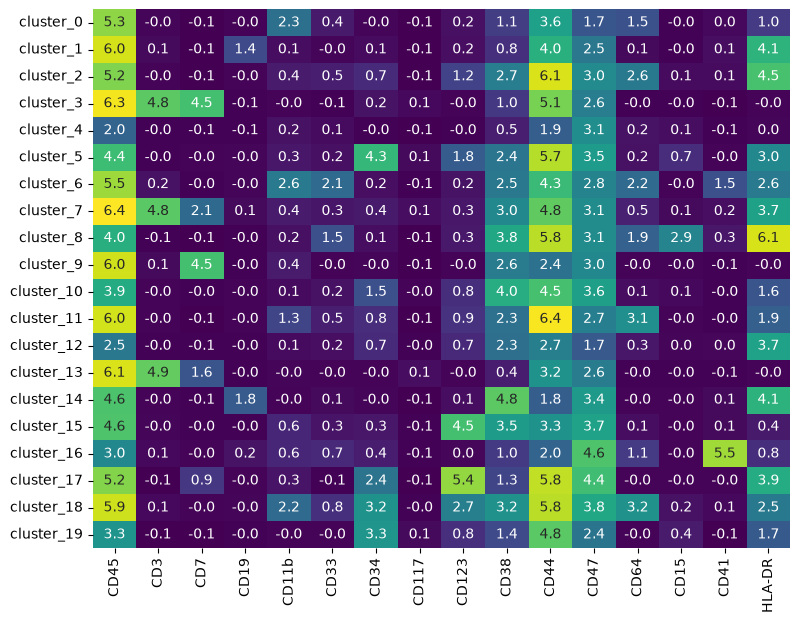

In [8]:
cluster_medians = sc.get.aggregate(adata[:, type_markers], by="cluster", func="median").to_df(layer="median")
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cluster_medians, annot=True, fmt=".1f", cmap="viridis", cbar=False, ax=ax)
ax.set(xlabel="", ylabel="");

Rather than typing a name for every cluster number, we write down the marker profile of each population as a rule on these medians. The leukaemic blasts of AML do not look like any normal cell type and differ between patients, so we name the myeloid populations by their markers rather than by cell type:

- `CD34+ progenitors/blasts`: CD34+ cells. In healthy marrow these are the few normal progenitors, in AML mostly blasts; the markers cannot tell the two apart.
- `CD34- myeloid`: CD34- cells with CD11b or CD64, such as monocytes and granulocyte precursors in healthy marrow, and more mature-looking blasts in AML.
- `T cells`, `NK cells` and `B cells`: CD3+; CD7+ CD3-; CD19+ HLA-DR+.
- `CD45 low`: cells with low CD45, such as red blood cell precursors and platelets.

The CD117 channel is low in all cells of these files, so no rule uses it. The rules are written so that a cluster can match at most one of them, and the code stops with an error if a cluster matches two or if a population is not found at all. Clusters that match no rule are called `other`.

In [9]:
leukocyte = "CD45 > 3.5 and CD34 < 2 and "
rules = {
    "CD34+ progenitors/blasts": "CD34 > 2 and CD3 < 1 and CD19 < 1",
    "CD34- myeloid": leukocyte + "(CD11b > 1.5 or CD64 > 1.2) and CD3 < 1 and CD19 < 1 and CD7 < 3",
    "T cells": leukocyte + "CD3 > 3",
    "NK cells": leukocyte + "CD7 > 3 and CD3 < 1 and CD19 < 1 and CD11b < 1.5 and CD64 < 1.2",
    "B cells": leukocyte + "CD19 > 1 and `HLA-DR` > 3 and CD3 < 1",
    "CD45 low": "CD45 < 3.5 and CD34 < 2",
}
matches = pd.DataFrame({name: cluster_medians.eval(rule) for name, rule in rules.items()})
assert matches.sum(axis=1).max() <= 1, "a cluster matches more than one rule"
assert matches.any(axis=0).all(), "a population was not found"
names = matches.idxmax(axis=1).where(matches.any(axis=1), "other")
adata.obs["population"] = pd.Categorical(adata.obs["cluster"].map(names), categories=[*rules, "other"])
pd.crosstab(adata.obs["population"], adata.obs["condition"], normalize="columns").round(3)

condition,healthy,AML
population,,
CD34+ progenitors/blasts,0.012,0.372
CD34- myeloid,0.290,0.444
T cells,0.352,0.073
NK cells,0.053,0.010
B cells,0.107,0.042
CD45 low,0.163,0.028
other,0.023,0.030


With other seeds (0 and 1) the cluster numbers change completely, but these rules give nearly the same proportions per group, and about 90% of the cells get the same name as here.

## Summarise each sample

Now we reduce the cells to one row per sample. For abundance, we count the cells of each population in each sample, and divide by the number of cells per sample to get proportions:

In [10]:
counts = pd.crosstab(adata.obs["sample_id"], adata.obs["population"])
proportions = counts.div(counts.sum(axis=1), axis=0)
proportions.round(3).head()

population,CD34+ progenitors/blasts,CD34- myeloid,T cells,NK cells,B cells,CD45 low,other
sample_id,,,,,,,
H1,0.023,0.276,0.329,0.048,0.139,0.157,0.029
H2,0.031,0.235,0.289,0.029,0.172,0.217,0.027
H3,0.006,0.405,0.189,0.051,0.081,0.251,0.016
H4,0.007,0.283,0.365,0.027,0.090,0.201,0.027
H5,0.005,0.280,0.446,0.090,0.088,0.072,0.019


The proportions per sample, as violin plots with one dot per sample:

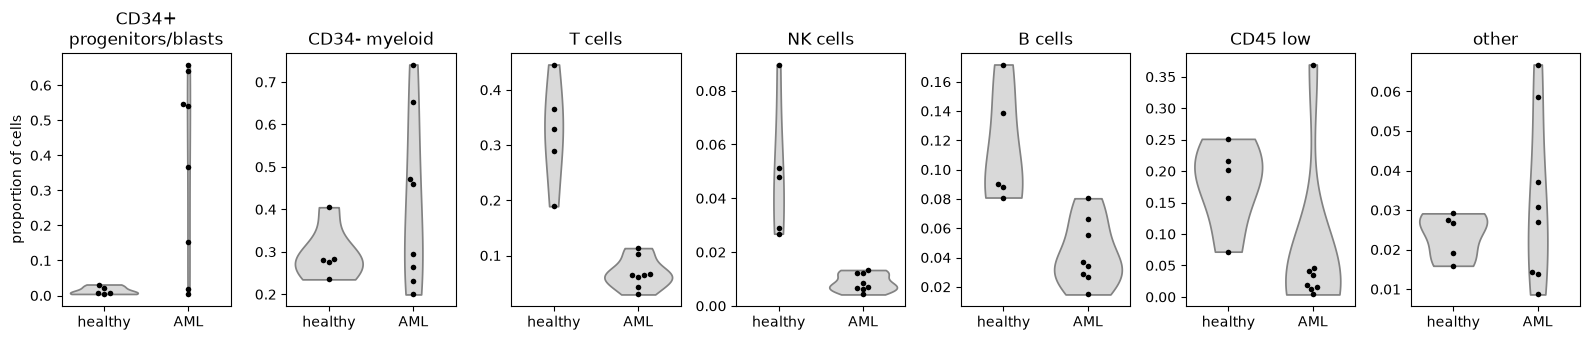

In [11]:
long_proportions = (
    proportions.stack().rename("proportion").reset_index().merge(samples[["sample_id", "condition"]], on="sample_id")
)
fig, axes = plt.subplots(1, proportions.shape[1], figsize=(16, 3.5))
for ax, (population, values) in zip(axes, long_proportions.groupby("population", observed=True), strict=True):
    sns.violinplot(values, x="condition", y="proportion", inner=None, cut=0, color="0.85", ax=ax)
    sns.swarmplot(values, x="condition", y="proportion", color="black", size=4, ax=ax)
    ax.set(title=population.replace(" progenitors/blasts", "\nprogenitors/blasts"), xlabel="", ylabel="")
axes[0].set_ylabel("proportion of cells")
fig.tight_layout()

The differences are large: CD34+ cells make up a large share of most AML samples and few percent of the healthy ones, while T, B and NK cells and CD45 low cells are rarer in AML. The AML samples also differ a lot from each other: AML is a heterogeneous disease, and the blasts of each patient look different.

## Differential abundance

Cell proportions are compositional: they add up to 1 in every sample, so when one population grows, all others shrink in proportion even if their absolute numbers do not change. Testing each population on its own ignores this. [scCODA](https://doi.org/10.1038/s41467-021-27150-6) models all populations of a sample together and measures every change relative to a reference population that is assumed not to change. It works well with few samples.

We chose T cells as the reference before looking at the results: they are present in every sample and, unlike the myeloid populations, they do not come from the leukaemic clone. All effects below are therefore changes relative to T cells. The only covariate is the condition, since every person gave one sample.

In [12]:
sccoda = pt.tl.Sccoda()
sccoda_data = sccoda.load(
    adata,
    type="cell_level",
    generate_sample_level=True,
    cell_type_identifier="population",
    sample_identifier="sample_id",
    covariate_obs=["condition"],
)
sccoda_data = sccoda.prepare(sccoda_data, formula="condition", reference_cell_type="T cells")
sccoda.run_nuts(sccoda_data, num_samples=5000, num_warmup=500, rng_key=1234)

scCODA calls an effect credible if it is included in the model with high probability, controlling the false discovery rate at 5% by default. The effects of AML:

In [13]:
effects = sccoda.get_effect_df(sccoda_data).loc["condition[T.AML]"]
effects["credible"] = sccoda.credible_effects(sccoda_data).loc["condition[T.AML]"]
effects[["Inclusion probability", "log2-fold change", "credible"]].round(2)

,Inclusion probability,log2-fold change,credible
Cell Type,,,
CD34+ progenitors/blasts,0.95,1.55,True
CD34- myeloid,0.44,-0.19,False
T cells,0.00,-0.19,False
NK cells,0.55,-0.19,False
B cells,0.52,-0.19,False
CD45 low,0.76,-0.19,False
other,0.39,-0.19,False


Only the increase of CD34+ progenitors/blasts is credible, with a log2-fold change of 1.6 relative to T cells. The other populations share a small common shift, because the proportions have to add up to 1.

This result is fragile. With FlowSOM seeds 0 and 1, the inclusion probability of the CD34+ effect is 0.94 and 0.84, just below the threshold, and no effect is credible. With 13 samples, and AML samples that differ this much from each other, scCODA stays cautious even for a difference that is easy to see in the plot. A larger cohort, or separate analyses of AML subtypes, would give a clearer answer.

## Differential state

For the state markers, we take the median of each marker over the cells of each population in each sample, with `sc.get.aggregate`. This gives an AnnData with one observation per sample and population and the medians in the layer `"median"`.

A median of very few cells is noisy, so we set a minimum of 50 cells per sample and population and drop the medians below it. We test only the populations that exist in both groups and still have at least 3 samples in each group; `CD45 low` and `other` are not well defined populations, so we leave them out.

In [14]:
pseudobulk = sc.get.aggregate(adata[:, state_markers], by=["sample_id", "population", "condition"], func="median")
pseudobulk = pseudobulk[pseudobulk.obs["n_obs_aggregated"] >= 50]
n_samples = pd.crosstab(pseudobulk.obs["population"], pseudobulk.obs["condition"])
tested = [p for p in n_samples.index[(n_samples >= 3).all(axis=1)] if p not in ["CD45 low", "other"]]
n_samples.loc[tested]

condition,healthy,AML
population,,
CD34+ progenitors/blasts,5,8
CD34- myeloid,5,8
T cells,5,8
NK cells,5,7
B cells,5,8


In every tested population, we compare the medians of the AML samples with those of the healthy samples with pertpy's `TTest`. Because the AML samples vary much more than the healthy ones, we use Welch's t-test (`equal_var=False`), which does not assume equal variances. pertpy's `log_fc` column assumes counts, so we compute the difference between the group means of the arcsinh medians ourselves. We correct the p-values with Benjamini-Hochberg over all tests together.

In [15]:
results = []
for population in tested:
    subset = pseudobulk[pseudobulk.obs["population"] == population]
    result = pt.tl.TTest.compare_groups(
        subset,
        column="condition",
        baseline="healthy",
        groups_to_compare="AML",
        layer="median",
        test_kwargs={"equal_var": False},
    )
    means = subset.to_df(layer="median").groupby(subset.obs["condition"], observed=True).mean()
    difference = (means.loc["AML"] - means.loc["healthy"]).rename("difference")
    results.append(result.join(difference, on="variable").assign(population=population))
results = pd.concat(results, ignore_index=True).rename(columns={"variable": "marker"})
results["adj_p_value"] = fdrcorrection(results["p_value"])[1]
significant = results[results["adj_p_value"] < 0.05].sort_values("difference", key=abs, ascending=False)
print(f"{len(significant)} of {len(results)} tests with adjusted p < 0.05")
significant[["population", "marker", "difference", "adj_p_value"]].head(10)

6 of 70 tests with adjusted p < 0.05


,population,marker,difference,adj_p_value
15,CD34- myeloid,pCREB,0.928277,0.005999
0,CD34+ progenitors/blasts,pCREB,0.665415,0.015951
14,CD34- myeloid,pAMPK,0.650722,0.005015
42,NK cells,pErk1-2,0.457006,0.005999
56,B cells,pErk1-2,0.319427,0.024687
28,T cells,pErk1-2,0.282077,0.029682


The heatmap shows the differences (AML minus healthy, on the arcsinh scale) of all tests with an adjusted p-value below 0.05:

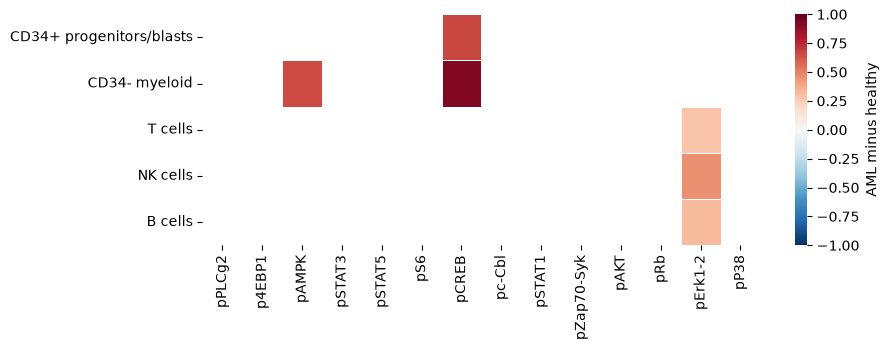

In [16]:
difference = results.pivot(index="population", columns="marker", values="difference").loc[tested, state_markers]
adj_p = results.pivot(index="population", columns="marker", values="adj_p_value").loc[tested, state_markers]
fig, ax = plt.subplots(figsize=(9, 3))
sns.heatmap(
    difference.where(adj_p < 0.05),
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar_kws={"label": "AML minus healthy"},
    ax=ax,
)
ax.set(xlabel="", ylabel="");

The per-sample medians of the four largest significant differences:

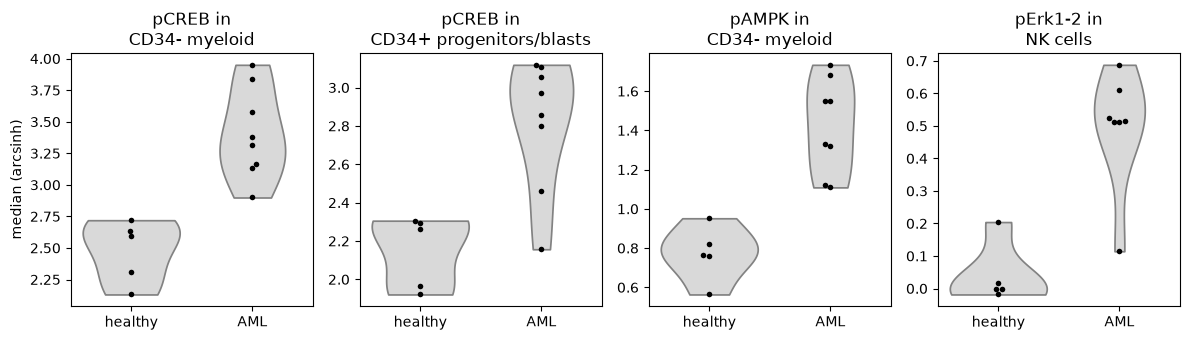

In [17]:
top = significant.head(4)
fig, axes = plt.subplots(1, 4, figsize=(12, 3.5))
for ax, row in zip(axes, top.itertuples(), strict=True):
    subset = pseudobulk[pseudobulk.obs["population"] == row.population]
    values = subset.obs[["condition"]].assign(median=subset.to_df(layer="median")[row.marker])
    sns.violinplot(values, x="condition", y="median", inner=None, cut=0, color="0.85", ax=ax)
    sns.swarmplot(values, x="condition", y="median", color="black", size=4, ax=ax)
    ax.set(title=f"{row.marker} in\n{row.population}", xlabel="", ylabel="")
axes[0].set_ylabel("median (arcsinh)")
fig.tight_layout()

Few tests are significant, and the differences are moderate: pCREB is higher in both myeloid populations of the AML samples and pAMPK in their CD34- myeloid cells (by 0.65 to 0.93 on the arcsinh scale), and pErk1-2 is higher in their T, B and NK cells (by 0.3 to 0.5). With seeds 0 and 1 the same results come out, except that pCREB in CD34+ cells is not significant with seed 1.

Lymphocytes are not part of the leukaemia, so their higher pErk1-2 may come from differences in how the healthy and AML samples were collected and processed rather than from the disease, and this data cannot tell the two apart. Some large differences, such as lower pSTAT1 in all populations of the AML samples (by 1 to 2), are not significant, because they vary a lot between the AML samples.

As an exercise, you can add the other 8 AML patients of the figshare dataset and see which results hold.

## Session info

In [18]:
import session_info2

session_info2.session_info()

Package,Version
pandas,3.1.0
arviz-stats,1.3.3
matplotlib,3.11.2
anndata,0.13.4
pertpy,1.4.0
pooch,1.9.0 (v1.9.0)
scanpy,1.12.4
seaborn,0.13.2
statsmodels,0.15.0
pytometry,0.2.0
